In [12]:
import keras
from keras.models import Sequential
from keras.layers import MaxPooling2D, Conv2D, Flatten, Dense, Dropout, BatchNormalization
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('dark_background')
from keras.utils import to_categorical
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [17]:
label_encoder = LabelEncoder()
label_encoder.fit(["angry", "happy", "sad"])
data =[]
labels=[]
for emotion_folder in ["angry", "happy", "sad"]:
    class_index = label_encoder.transform([emotion_folder])[0]
    class_label = to_categorical(class_index, num_classes=3)
    paths = []
    for r, d, f in os.walk(os.path.join(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Emotion Detection", emotion_folder)):
        for file in f:
            if file.lower().endswith(('.jpg', '.jpeg','.png')):
                paths.append(os.path.join(r, file))

        for path in paths:
            try:
              img = Image.open(path).convert("RGB")
              img = img.resize((128, 128))
              img = np.array(img)

              data.append(img)
              labels.append(class_label)

            except Exception as e:
               print("Error:", path, e)
data = np.array(data)
labels = np.array(labels)

print(data.shape)
print(labels.shape)

(3972, 128, 128, 3)
(3972, 3)


In [18]:
data = np.array(data)
data.shape

(3972, 128, 128, 3)

In [19]:
result = np.array(labels)
result=result.reshape(3972, -1)

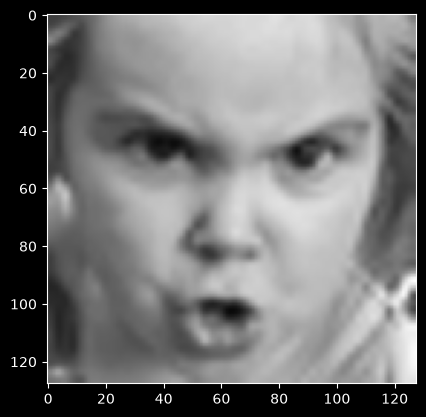

In [20]:
plt.imshow(data[10])

In [21]:
x_train,x_test,y_train,y_test = train_test_split(data,result, test_size=0.2, shuffle=True, random_state=42)

In [22]:
output_classes = 3

model = Sequential()

model.add(Conv2D(32, kernel_size=(2, 2), input_shape=(128, 128, 3), padding = 'Same'))
model.add(Conv2D(32, kernel_size=(2, 2),  activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))

print(model.summary())

c:\Users\vimal_z0\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    33,554,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,586,115 (128.12 MB)

 Trainable params: 33,585,923 (128.12 MB)

 Non-trainable params: 192 (768.00 B)

None


In [23]:
model.compile(loss = "categorical_crossentropy", optimizer='Adam',metrics=['accuracy'])

In [24]:
x_train.shape

(3177, 128, 128, 3)

In [25]:
y_train.shape

(3177, 3)

In [26]:
history = model.fit(x_train, y_train, epochs = 10, batch_size = 20, verbose = 1,validation_data = (x_test, y_test))

Epoch 1/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.4101 - loss: 4.3416 - val_accuracy: 0.3145 - val_loss: 2.1983
Epoch 2/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 240s 1s/step - accuracy: 0.4451 - loss: 1.0848 - val_accuracy: 0.3761 - val_loss: 1.1635
Epoch 3/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 515s 3s/step - accuracy: 0.4586 - loss: 1.0696 - val_accuracy: 0.4302 - val_loss: 1.1311
Epoch 4/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 363s 2s/step - accuracy: 0.4624 - loss: 1.0546 - val_accuracy: 0.2830 - val_loss: 1.4410
Epoch 5/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 969s 6s/step - accuracy: 0.4602 - loss: 1.0627 - val_accuracy: 0.4604 - val_loss: 1.1807
Epoch 6/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 439s 2s/step - accuracy: 0.4696 - loss: 1.0481 - val_accuracy: 0.4579 - val_loss: 1.3655
Epoch 7/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.4794 - loss: 1.0376 - val_accuracy: 0.4579 - val_loss: 1.3320
Epoch 8/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 262s 2s/step - accuracy: 0.4825 - loss: 1.0332 - val_accu

In [27]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 241ms/step - accuracy: 0.3220 - loss: 2.0969
Test Accuracy: 0.3220125734806061


In [29]:
def names(number):
    if number==0:
        return "angry"
    elif number==1:
        return "happy"
    else:
        return "sad"

In [43]:
print("Model Input Shape:", model.input_shape)
print("Image Array Shape:", np.array(img).shape)

Model Input Shape: (None, 128, 128, 3)
Image Array Shape: (48, 48)


96.4624% Confidence This Is sad


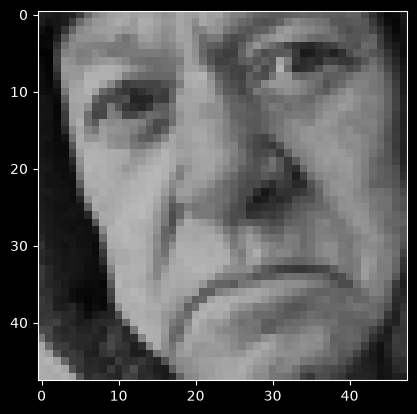

In [54]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Emotion Detection\angry\im12.png")
img = img.convert("RGB")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

80.96722% Confidence This Is sad


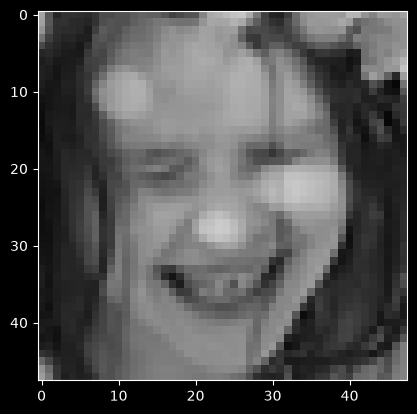

In [50]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Emotion Detection\happy\im10.png")
img = img.convert("RGB")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

46.703896% Confidence This Is sad


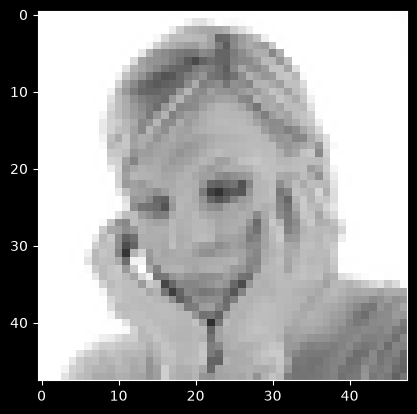

In [51]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Emotion Detection\sad\im8.png")
img = img.convert("RGB")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))